<a href="https://colab.research.google.com/github/AymenGTARI/real-time-object-classification/blob/main/Classification%20des%20D%C3%A9chets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#  Bloc 1: Monter Google Drive et importer les bibliothèques
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import Counter
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#  Bloc 2: Définir les paramètres
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 5
dataset_paths = [
    "/content/drive/MyDrive/TrashType_Image_Dataset",
    "/content/drive/MyDrive/extras"
]

In [ ]:
#  Bloc 3: Construction du DataFrame depuis les chemins d’images
data = []
for dataset_path in dataset_paths:
    if os.path.exists(dataset_path):
        for label in os.listdir(dataset_path):
            folder_path = os.path.join(dataset_path, label)
            if os.path.isdir(folder_path):
                for file in os.listdir(folder_path):
                    if file.lower().endswith(('jpg', 'jpeg', 'png')):
                        data.append((os.path.join(folder_path, file), label))

df = pd.DataFrame(data, columns=['filepath', 'label']).sample(frac=1, random_state=42).reset_index(drop=True)
print(f"Total images: {len(df)}, Classes: {df['label'].nunique()}")

Total images: 2527, Classes: 6


In [ ]:
#  Bloc 4: Nettoyage du dataset (images corrompues ou non-RGB)
invalid_images = []
for i, row in df.iterrows():
    try:
        with Image.open(row['filepath']) as img:
            if img.mode != 'RGB':
                invalid_images.append(i)
    except:
        invalid_images.append(i)

df.drop(index=invalid_images, inplace=True)
df.reset_index(drop=True, inplace=True)

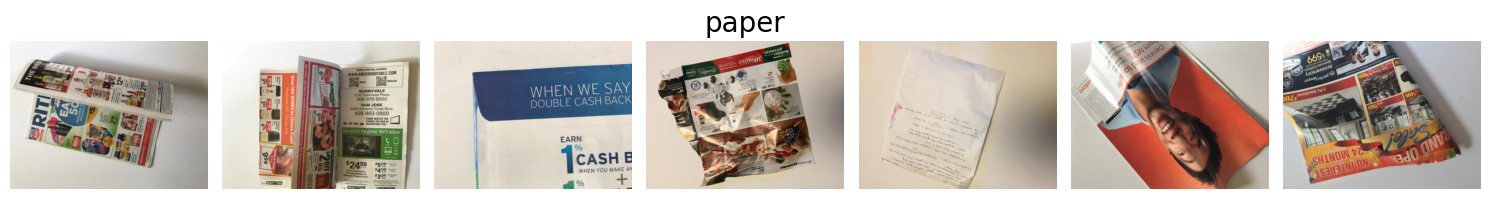

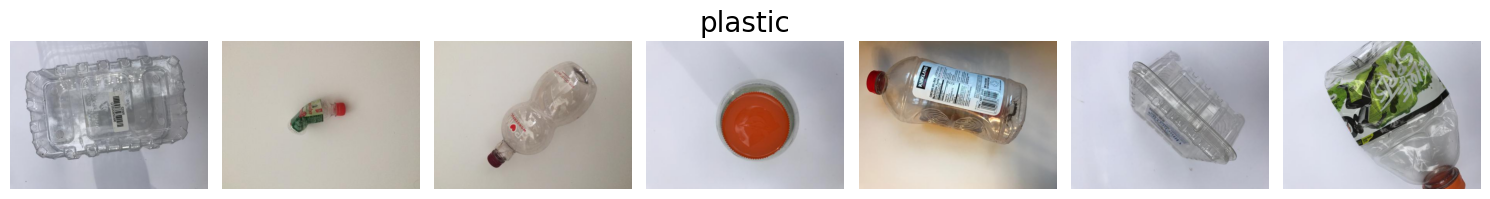

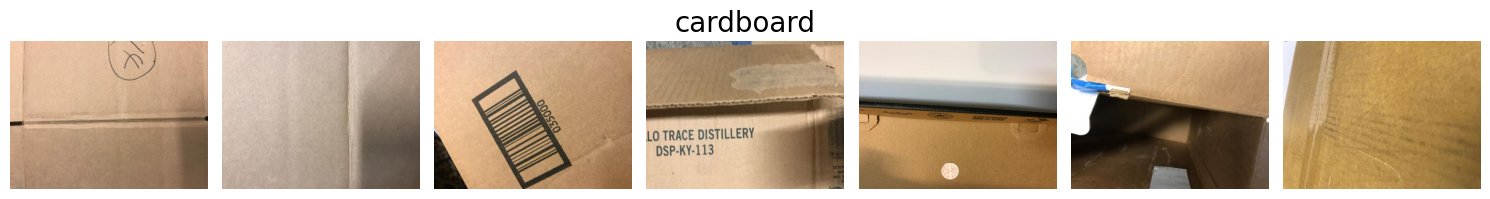

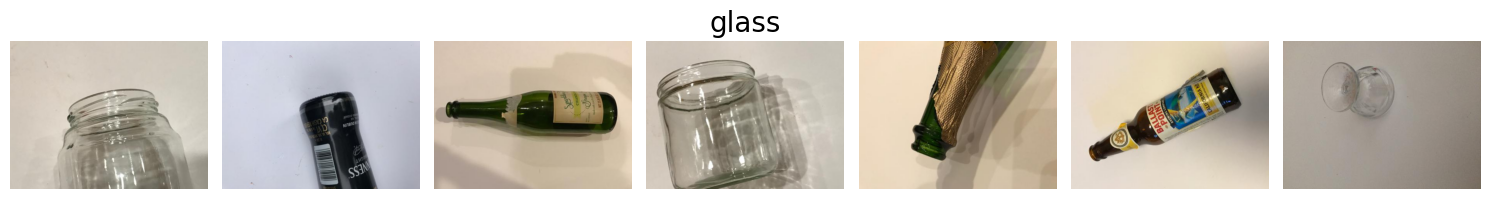

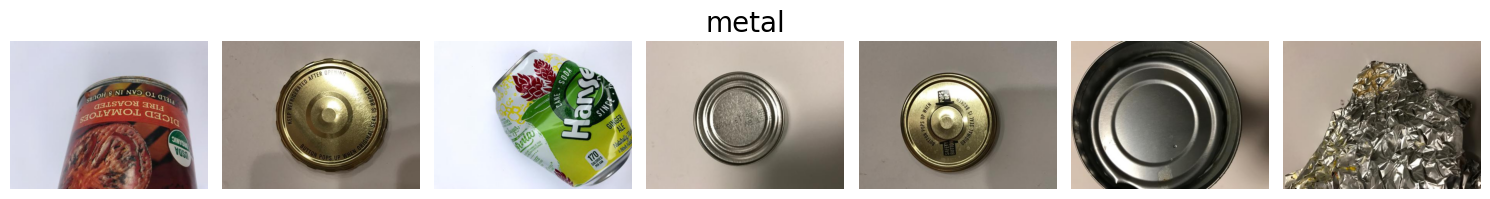

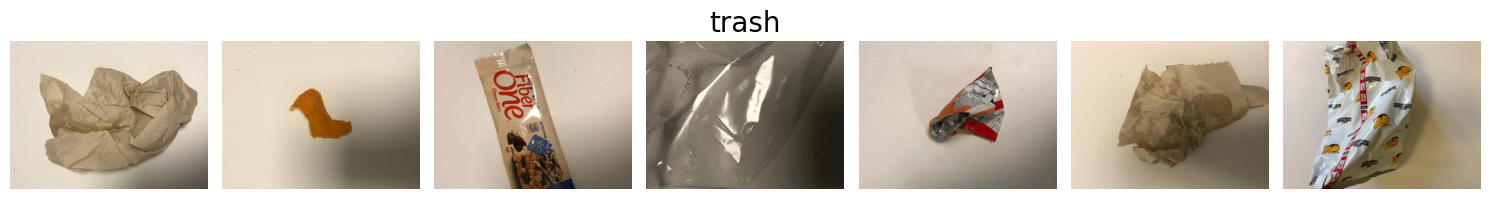

In [ ]:
# Bloc 4.1: Affichage de quelques images par type de déchet


garbage_types = df['label'].unique()
base_path = None


for path in dataset_paths:
    if os.path.exists(path):
        base_path = path
        break


for garbage_type in garbage_types:
    folder_path = os.path.join(base_path, garbage_type)

    if os.path.isdir(folder_path):
        image_files = [f for f in os.listdir(folder_path) if f.lower().endswith(('jpg', 'jpeg', 'png'))]
        image_files = image_files[:7]

        fig, axs = plt.subplots(1, len(image_files), figsize=(15, 2))

        for i, image_file in enumerate(image_files):
            image_path = os.path.join(folder_path, image_file)
            with Image.open(image_path) as img:
                axs[i].imshow(img)
                axs[i].axis('off')

        plt.tight_layout()
        fig.suptitle(garbage_type, fontsize=20, y=1.03)
        plt.show()


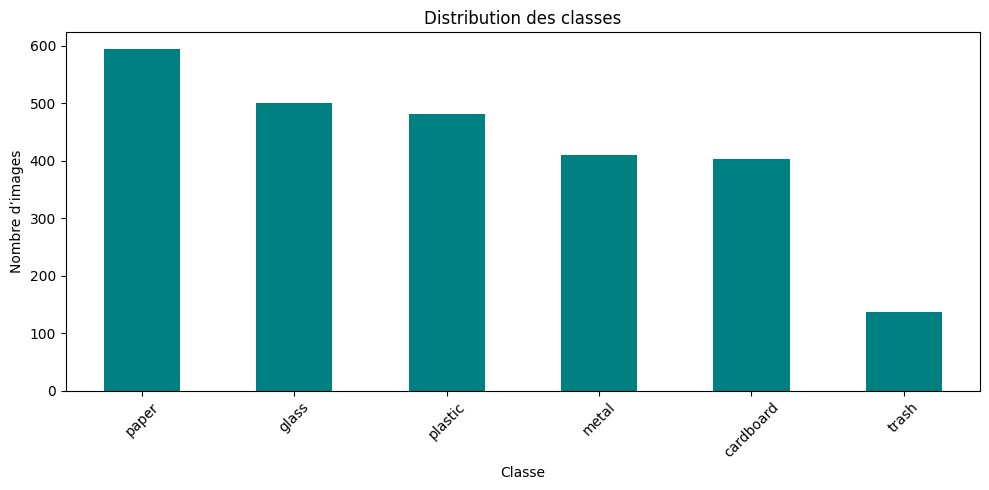

In [ ]:
#  Bloc 5: Visualisation de la distribution des classes
plt.figure(figsize=(10, 5))
df['label'].value_counts().plot(kind='bar', color='teal')
plt.title("Distribution des classes"); plt.xlabel("Classe"); plt.ylabel("Nombre d’images")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

In [ ]:
#  Bloc 6: Création de répertoires temporaires pour `flow_from_directory`
import shutil
import tempfile

base_dir = tempfile.mkdtemp()
for _, row in df.iterrows():
    label_dir = os.path.join(base_dir, row['label'])
    os.makedirs(label_dir, exist_ok=True)
    shutil.copy(row['filepath'], label_dir)


In [ ]:
#  Bloc 7: Préparation des générateurs de données
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2]
)

train_generator = train_datagen.flow_from_directory(
    base_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

val_generator = train_datagen.flow_from_directory(
    base_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)


Found 2024 images belonging to 6 classes.
Found 503 images belonging to 6 classes.


In [ ]:
#  Bloc 8: Calcul des poids de classe
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)
class_weights_dict = dict(enumerate(class_weights))
print("Poids de classe:", class_weights_dict)

Poids de classe: {0: np.float64(1.04437564499484), 1: np.float64(0.8412302576891105), 2: np.float64(1.0284552845528456), 3: np.float64(0.7086834733893558), 4: np.float64(0.8739205526770294), 5: np.float64(3.066666666666667)}


In [ ]:
#  Bloc 9: Construction du modèle CNN avec ResNet50
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128)(x)
x = BatchNormalization()(x)
x = tf.keras.activations.relu(x)
x = Dropout(0.5)(x)
output = Dense(len(train_generator.class_indices), activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,851,270 (90.99 MB)

 Trainable params: 263,302 (1.00 MB)

 Non-trainable params: 23,587,968 (89.98 MB)

In [ ]:
#  Bloc 10: Entraînement du modèle
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=[early_stop],
    class_weight=class_weights_dict,
    verbose=1
)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 468s 7s/step - accuracy: 0.2406 - loss: 2.1111 - val_accuracy: 0.6143 - val_loss: 1.0632
Epoch 2/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 459s 7s/step - accuracy: 0.5609 - loss: 1.1548 - val_accuracy: 0.7018 - val_loss: 0.7635
Epoch 3/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 446s 7s/step - accuracy: 0.6458 - loss: 0.9477 - val_accuracy: 0.7575 - val_loss: 0.6818
Epoch 4/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 498s 8s/step - accuracy: 0.7146 - loss: 0.7723 - val_accuracy: 0.7714 - val_loss: 0.6445
Epoch 5/5
64/64 ━━━━━━━━━━━━━━━━━━━━ 444s 7s/step - accuracy: 0.7599 - loss: 0.7197 - val_accuracy: 0.7913 - val_loss: 0.5998


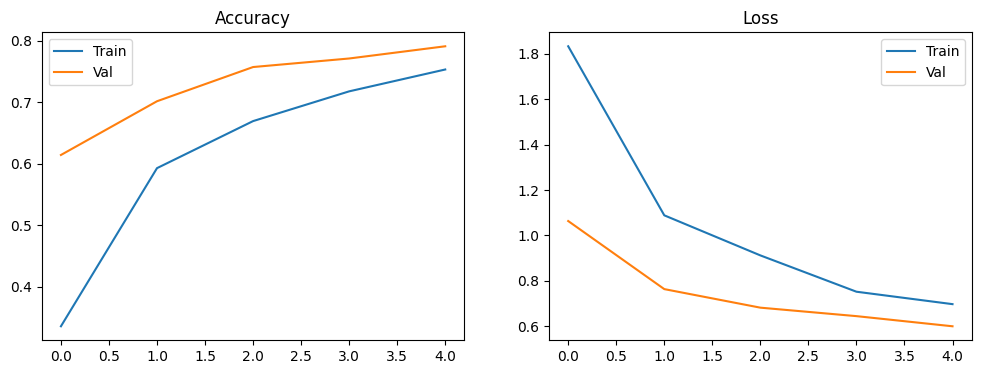

In [ ]:
#  Bloc 11: Visualisation de la performance
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1); plt.plot(acc, label='Train'); plt.plot(val_acc, label='Val'); plt.title("Accuracy"); plt.legend()
plt.subplot(1, 2, 2); plt.plot(loss, label='Train'); plt.plot(val_loss, label='Val'); plt.title("Loss"); plt.legend()
plt.show()


16/16 ━━━━━━━━━━━━━━━━━━━━ 93s 6s/step
              precision    recall  f1-score   support

   cardboard       0.93      0.95      0.94        80
       glass       0.88      0.70      0.78       100
       metal       0.85      0.84      0.85        82
       paper       0.82      0.79      0.80       118
     plastic       0.76      0.71      0.73        96
       trash       0.36      0.74      0.48        27

    accuracy                           0.79       503
   macro avg       0.76      0.79      0.76       503
weighted avg       0.81      0.79      0.80       503



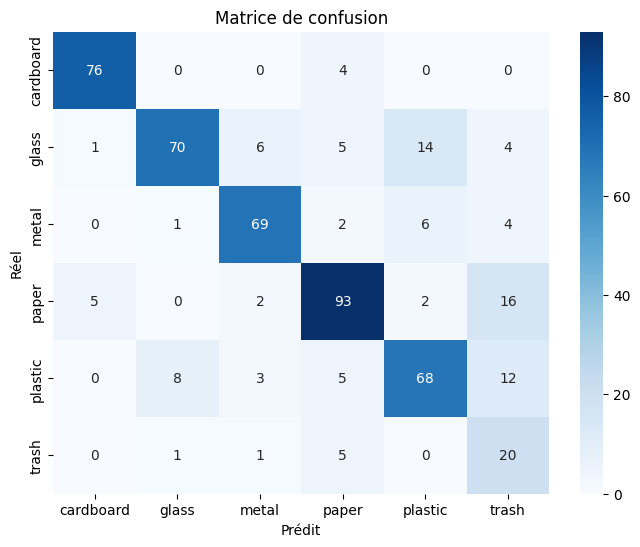

In [ ]:
#  Bloc 12: Évaluation sur l'ensemble de validation
val_generator.reset()
preds = model.predict(val_generator)
y_pred = np.argmax(preds, axis=1)
y_true = val_generator.classes
labels = list(val_generator.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=labels))
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.title("Matrice de confusion")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
 Prédiction pour l'image : plastic_1049.jpg
cardboard : 1.14%
glass : 25.88%
metal : 0.63%
paper : 4.09%
plastic : 65.26%
trash : 3.01%


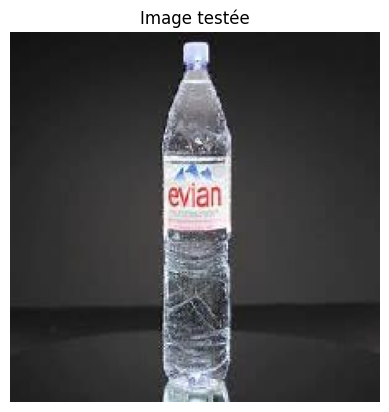

In [ ]:
#  Bloc 13: Prédiction sur une image test
from tensorflow.keras.preprocessing import image

test_image_path = '/content/drive/MyDrive/plastic_1049.jpg'
img = image.load_img(test_image_path, target_size=IMG_SIZE)
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)

predictions = model.predict(img_array)[0]
class_labels = list(train_generator.class_indices.keys())

print(f" Prédiction pour l'image : {os.path.basename(test_image_path)}")
for label, prob in zip(class_labels, predictions):
    print(f"{label} : {prob * 100:.2f}%")

plt.imshow(img); plt.axis('off'); plt.title("Image testée"); plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step
Prédiction sur l'image : glass_1145.jpg
cardboard : 1.42%
glass : 91.39%
metal : 1.07%
paper : 1.38%
plastic : 2.59%
trash : 2.15%


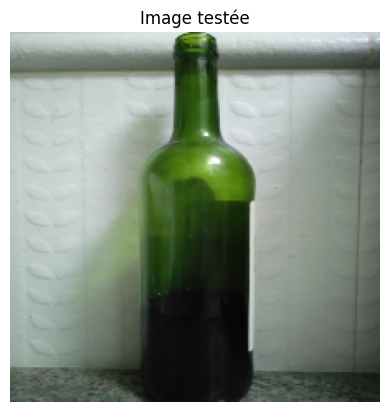

In [ ]:
# Bloc 11: Prédiction sur une image test avec pourcentages de confiance

from tensorflow.keras.preprocessing import image

# Chemin de l'image de test à modifier selon ton image
test_image_path = '/content/drive/MyDrive/glass_1145.jpg'

# Charger et prétraiter l'image
img = image.load_img(test_image_path, target_size=IMG_SIZE)
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)

# Prédiction
predictions = model.predict(img_array)
confidence_scores = predictions[0]

# Récupération des noms de classes
class_labels = list(train_generator.class_indices.keys())

# Afficher les résultats
print("Prédiction sur l'image :", os.path.basename(test_image_path))
for i, score in enumerate(confidence_scores):
    print(f"{class_labels[i]} : {score*100:.2f}%")

# Optionnel : afficher l'image testée
plt.imshow(img)
plt.axis('off')
plt.title("Image testée")
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step
Prédiction sur l'image : trash_102.jpg
cardboard : 1.12%
glass : 8.49%
metal : 33.46%
paper : 2.78%
plastic : 16.05%
trash : 38.10%


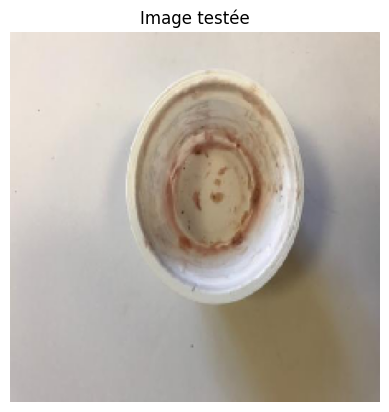

In [ ]:
# Bloc 11: Prédiction sur une image test avec pourcentages de confiance

from tensorflow.keras.preprocessing import image

# Chemin de l'image de test à modifier selon ton image
test_image_path = '/content/drive/MyDrive/trash_102.jpg'

# Charger et prétraiter l'image
img = image.load_img(test_image_path, target_size=IMG_SIZE)
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)

# Prédiction
predictions = model.predict(img_array)
confidence_scores = predictions[0]

# Récupération des noms de classes
class_labels = list(train_generator.class_indices.keys())

# Afficher les résultats
print("Prédiction sur l'image :", os.path.basename(test_image_path))
for i, score in enumerate(confidence_scores):
    print(f"{class_labels[i]} : {score*100:.2f}%")

# Optionnel : afficher l'image testée
plt.imshow(img)
plt.axis('off')
plt.title("Image testée")
plt.show()
